# Libraries

In [37]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Dataset

In [2]:
df_raw = pd.read_csv("processed_data/encoded.csv")

In [3]:
df = df_raw.copy()
independent_variable = "G2"
dependent_variable = "G3"
df = df[[independent_variable, dependent_variable]]
df.rename(columns={
    "G2" : "x",
    "G3" : "y"
    }, inplace=True)

# Visualization

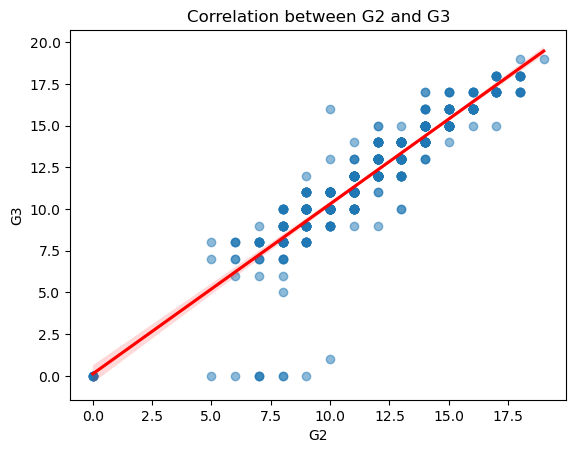

In [4]:
sns.regplot(
    data=df,
    x='x',
    y='y',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title(f'Correlation between {independent_variable} and {dependent_variable}')
plt.xlabel(f"{independent_variable}")
plt.ylabel(f"{dependent_variable}")
plt.show()

Looks like some students quit:
* all of them never got "sufficient" scores before
* some quit during G3, others even before (G2)
* many of them already have past failures

In [5]:
df_raw.loc[df_raw["G3"] < 5,
["G1", "G2", "G3", "failures"]]

,G1,G2,G3,failures
163,11,9,0,2
172,10,10,1,1
440,7,0,0,0
519,8,7,0,0
563,7,0,0,1
567,4,0,0,1
583,8,6,0,1
586,8,8,0,0
597,9,0,0,1
603,5,0,0,0


# Regression

In [6]:
X = df['x']
y = df['y']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.844
Model:                            OLS   Adj. R-squared:                  0.843
Method:                 Least Squares   F-statistic:                     3493.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          5.64e-263
Time:                        20:33:11   Log-Likelihood:                -1079.1
No. Observations:                 649   AIC:                             2162.
Df Residuals:                     647   BIC:                             2171.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1220      0.206      0.593      0.5

* R-squared = *fraction of the variability of y explained by x*
    * 84% of variability explained
* Adjusted R-squared = *accounts for the number of independent variables. In simple linear regression, it is very similar to R-squared*
    * 84% of variability explained
* P>|t| = *p-value of the coefficient, with the Null Hypothesis $H_0 : coef = 0$. When lower than 0.05, the coefficient is considered statistically significant*
    * intercept Failed to reject $H_0$, so not statistically significant
    * slope Reject $H_0$, so statistically significant
* 0.025 and 0.975 = confidence intervals of the coefficient (95% confidence)

## Checking assumptions

The assumptions of the linear regression are:
* linearity (of data and residuals)
    * graph of data
    * graph of residuals
* independence of errors (Durbin-Watson)
* homoscedasticity (equally dispersed)
    * graph
    * Breusch-Pagan
* normally distributed
    * Q-Q plot
    * Shapiro-Wilk

### Residuals

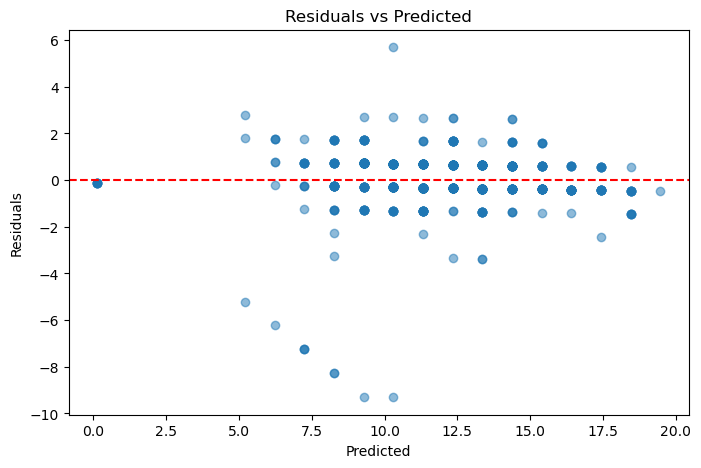

In [7]:
residuals = model.resid
predicted = model.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

From this plot, I can tell residuals are linear and homoscedastic.\
Outliers are clearly present (the ones who quit already noticed, but also someone who performed way better than expected).

### Independence of errors

This test (Durbin-Watson) is usually employed for time series, so this is not the typical case

Durbin-Watson was in the statistics of the regression (1.84).
* dw ranges from 0 to 4
* dw close to 2 = no autocorrelation
* dw close to 0 = positive autocorrelation
* dw close to 4 = negative autocorrelation

### Homoscedasticity

Alongside the dispersion of residuals, the Breusch-Pagan test can be performed.\
Null Hypothesis = homoscedasticity

In case of heteroscedasticity, the model of linear regression con be performed again with another method (HC3), more robust to heteroscedasticity

In [8]:
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(15.758765885039068), 'LM p-value': np.float64(7.195375552498937e-05), 'F Statistic': np.float64(16.101164893139753), 'F p-value': np.float64(6.706791477994098e-05)}


Data are clearly heteroscedastic.\
The model with HC3 does not change coefficients, but changes the way standard errors are calculated, affecting p-values and confidence intervals.

Even with the robust regression, the coefficient of X is still significant, while the intercept is not

In [9]:
model_robust = model.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.844
Model:                            OLS   Adj. R-squared:                  0.843
Method:                 Least Squares   F-statistic:                     2558.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          5.65e-227
Time:                        20:33:11   Log-Likelihood:                -1079.1
No. Observations:                 649   AIC:                             2162.
Df Residuals:                     647   BIC:                             2171.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1220      0.267      0.457      0.6

### Normality of residuals

Quantile-Quantile plot compares the residuals of a normal distribution with the residuals of the data.\
In this case, the tail of the data is attributed to outliers

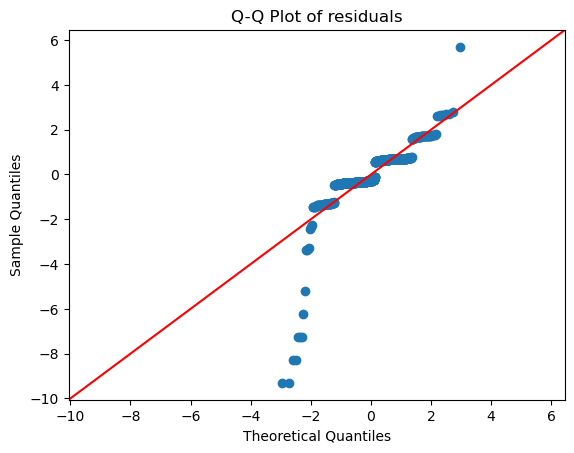

In [10]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot of residuals')
plt.show()

Shapiro-Wilk test, assumes*
* $H_0$ : Residuals follow a normal distribution
* $H_1$ : Residuals DO NOT follow a normal distribution

In [11]:
stat, p_value = shapiro(model.resid)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.7108466322173596
P-value: 6.059645639369248e-32


Again, the assumption of normality of residuals is violated, because of the outliers

## Candidate outliers

Standardized residuals:
* between +2 and -2 -> not anomalous
* absolute between 2 and 3 -> attention
* absolute > 3 -> candidate outliers

In [12]:
infl = model.get_influence()

df['standardized_residuals'] = (
    infl.resid_studentized_internal
)

outlier = df[
    np.abs(df['standardized_residuals']) > 3
]

print(outlier)

      x   y  standardized_residuals
61   10  16                4.458822
163   9   0               -7.277342
172  10   1               -7.289079
519   7   0               -5.688799
583   6   0               -4.894320
586   8   0               -6.482995
626   5   0               -4.099120
637   7   0               -5.688799
639   8   0               -6.482995
640   7   0               -5.688799


## Influence

This time the focus is on students with high impact on the regression. The difference with outliers is:
* outliers = predicted is much different from actual
* influent = if removed, would alter significantly the regression

Cook's distance combines:
* the distance of an observation from its prediction
* its *leverage*, that is how much its position is different from other observations

As an explorative criterion, often 

$D_i > 4/n$, where n = observations

is the threshold (below, the influence is little). If the distance is close to 1 or even higher, the influence is very high

In [13]:
influence = model.get_influence()

cooks_distance = influence.cooks_distance[0]

df['cooks_distance'] = cooks_distance

print(
    df.sort_values(
        'cooks_distance',
        ascending=False
    ).head(10)
)

      x  y  standardized_residuals  cooks_distance
519   7  0               -5.688799        0.086831
637   7  0               -5.688799        0.086831
640   7  0               -5.688799        0.086831
583   6  0               -4.894320        0.086628
639   8  0               -6.482995        0.081384
586   8  0               -6.482995        0.081384
626   5  0               -4.099120        0.079618
163   9  0               -7.277342        0.072797
172  10  1               -7.289079        0.052943
518   5  8                2.189782        0.022721


In [14]:
cooks_threshold = 4 / len(df)
print(cooks_threshold)

0.0061633281972265025


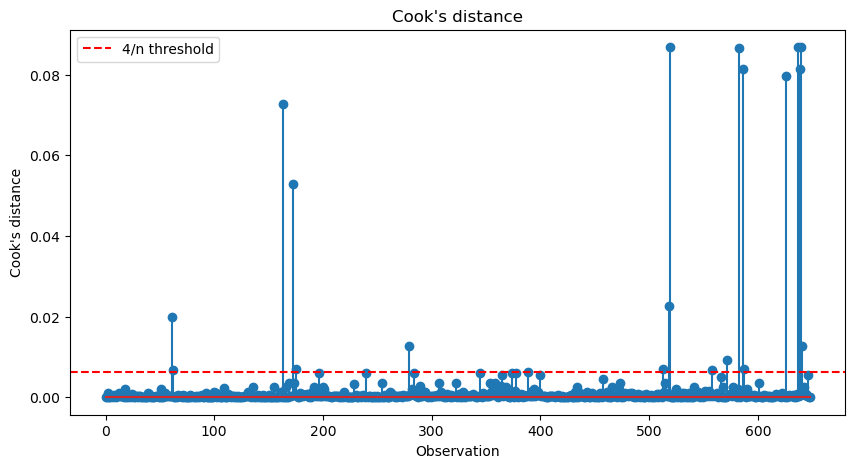

In [15]:
plt.figure(figsize=(10, 5))

plt.stem(
    np.arange(len(df)),
    df['cooks_distance']
)

plt.axhline(
    cooks_threshold,
    color='red',
    linestyle='--',
    label='4/n threshold'
)

plt.xlabel('Observation')
plt.ylabel("Cook's distance")
plt.title("Cook's distance")
plt.legend()
plt.show()

# Regression without outliers

Only people who quit (G3 results = 0 or 1) will be considered outliers, since they did not perform the test or did not even study, altering the dataset.

There are also people who quit even before G3 (in G2), which were not detected as outliers since there was a perfect correlation 0-0

In [16]:
df.drop(columns=["standardized_residuals", "cooks_distance"], inplace=True)

In [17]:
print(df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print(df.shape)

(649, 2)
(633, 2)


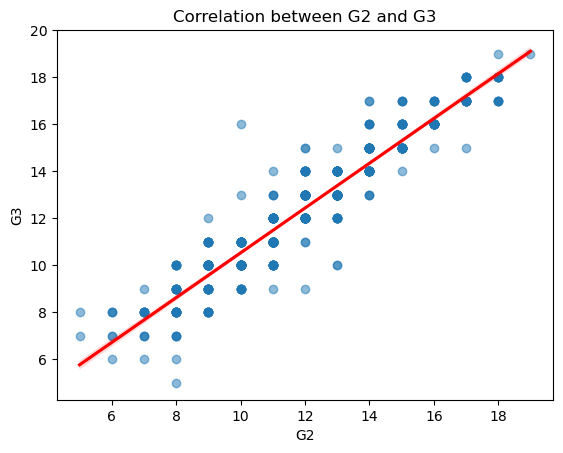

In [18]:
sns.regplot(
    data=df,
    x='x',
    y='y',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title(f'Correlation between {independent_variable} and {dependent_variable}')
plt.xlabel(f"{independent_variable}")
plt.ylabel(f"{dependent_variable}")
plt.show()

In [20]:
X = df['x']
y = df['y']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.888
Method:                 Least Squares   F-statistic:                     5037.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          5.46e-303
Time:                        20:35:04   Log-Likelihood:                -821.44
No. Observations:                 633   AIC:                             1647.
Df Residuals:                     631   BIC:                             1656.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0079      0.162      6.234      0.0

* R-squared = *fraction of the variability of y explained by x*
    * 89% of variability explained
* Adjusted R-squared = *accounts for the number of independent variables. In simple linear regression, it is very similar to R-squared*
    * 89% of variability explained
* P>|t| = *p-value of the coefficient, with the Null Hypothesis $H_0 : coef = 0$. When lower than 0.05, the coefficient is considered statistically significant*
    * Reject $H_0$, so statistically significant for both coefficients

## Checking assumptions

Resuming all assumptions:
* linearity (of data and residuals)
    * graph of data -> OK
    * graph of residuals -> OK, some extreme values
* independence of errors (Durbin-Watson) -> OK
* homoscedasticity (equally dispersed)
    * graph -> some extreme values
    * Breusch-Pagan -> heteroscedastic
* normally distributed -> violated
    * Q-Q plot
    * Shapiro-Wilk

### Residuals

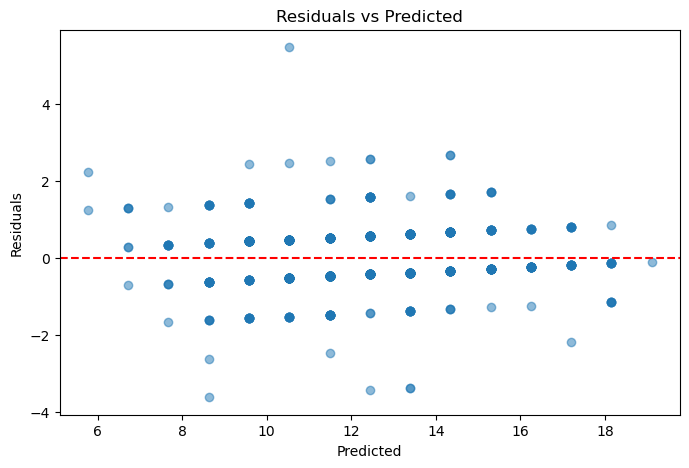

In [21]:
residuals = model.resid
predicted = model.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

### Independence of errors

Durbin-Watson = (1.78) = no autocorrelation

### Homoscedasticity

In [22]:
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(4.6100887587846735), 'LM p-value': np.float64(0.03178438809523035), 'F Statistic': np.float64(4.6292372852505705), 'F p-value': np.float64(0.03181036342360726)}


Data are still heteroscedastic.

Even with the robust regression, both coefficients are still significant

In [24]:
model_robust = model.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.888
Method:                 Least Squares   F-statistic:                     5204.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          5.54e-307
Time:                        20:39:09   Log-Likelihood:                -821.44
No. Observations:                 633   AIC:                             1647.
Df Residuals:                     631   BIC:                             1656.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0079      0.166      6.074      0.0

### Normality of residuals

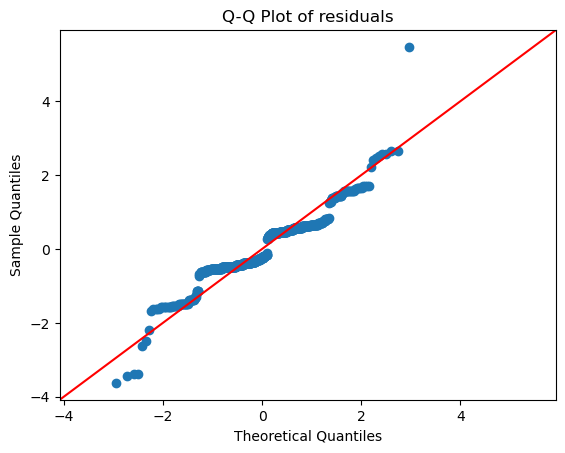

In [25]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot of residuals')
plt.show()

Shapiro-Wilk test
* $H_0$ : Residuals follow a normal distribution
* $H_1$ : Residuals DO NOT follow a normal distribution

In [26]:
stat, p_value = shapiro(model.resid)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.9295665829024643
P-value: 1.1427267036326706e-16


Again, the assumption of normality of residuals is violated

* Estimate of coefficients and errors are separate concepts
* alongside the normality of residuals, the distribution of estimated of coefficients with a large sample (N = 633) is also important
* with the central limit theorem, the distribution of coefficients can be approximated as normal even if individual errors are not normally distributed, because the estimate of coefficients becomes more accurate with large datasets 

## Candidate outliers

In [27]:
infl = model.get_influence()

df['standardized_residuals'] = (
    infl.resid_studentized_internal
)

outlier = df[
    np.abs(df['standardized_residuals']) > 3
]

print(outlier)

      x   y  standardized_residuals
61   10  16                6.169914
62   13  10               -3.824099
279   8   5               -4.098353
365  14  17                3.000057
400  14  17                3.000057
558  13  10               -3.824099
646  12   9               -3.877108


## Influence

In [28]:
influence = model.get_influence()

cooks_distance = influence.cooks_distance[0]

df['cooks_distance'] = cooks_distance

print(
    df.sort_values(
        'cooks_distance',
        ascending=False
    ).head(10)
)

      x   y  standardized_residuals  cooks_distance
61   10  16                6.169914        0.043609
279   8   5               -4.098353        0.040581
518   5   8                2.528651        0.038914
641  17  15               -2.488620        0.024564
284   8   6               -2.968510        0.021290
62   13  10               -3.824099        0.014165
558  13  10               -3.824099        0.014165
389   9  12                2.732408        0.012430
365  14  17                3.000057        0.012325
400  14  17                3.000057        0.012325


In [29]:
cooks_threshold = 4 / len(df)
print(cooks_threshold)

0.00631911532385466


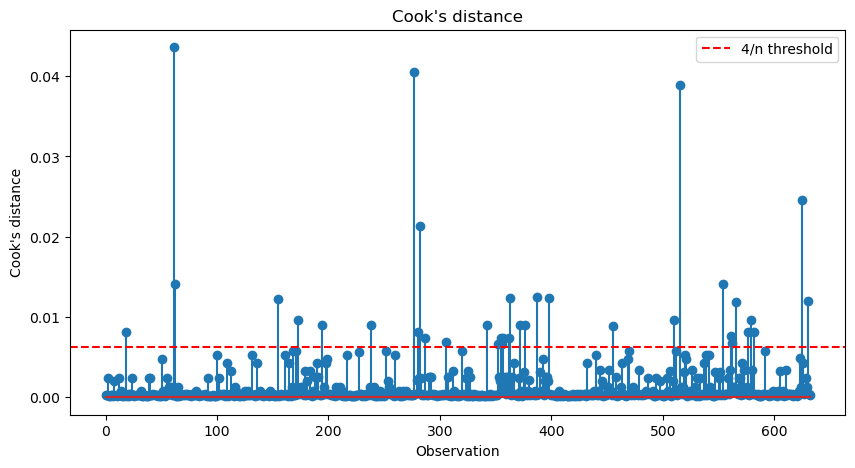

In [30]:
plt.figure(figsize=(10, 5))

plt.stem(
    np.arange(len(df)),
    df['cooks_distance']
)

plt.axhline(
    cooks_threshold,
    color='red',
    linestyle='--',
    label='4/n threshold'
)

plt.xlabel('Observation')
plt.ylabel("Cook's distance")
plt.title("Cook's distance")
plt.legend()
plt.show()

# Conclusions

> Heteroscedasticity of residuals

Heteroscedasticity means that the variance of errors is not constant with respect to the values of the independent variable or predicted values.\
It `does not distort estimates of coefficients` of OLS regression.\
Heteroscedasticity-Consistent Standard Errors were calculated with the correction HC3 (best in small/medium samples, when there are observations with high leverage).\
For calculations on p-values and confidence intervals, the HC3 correction is more reliable.

> Non-normality of residuals

It `does not distort estimates of coefficients` of OLS regression.\
Even if the Shapiro-Wilk test Rejected the Hypothesis of a normal distribution, the Q-Q plot shows that the majority of observations follow the expected trend, with some exceptions at the tails, suggesting that deviations from normality are not marked for the majority of observations.\
Considering the number of observations (N = 633), asymptotic properties of OLS estimators and the `central limit theorem` can be employed to approximate the distribution of estimators to a normal distribution, even if the distribution of residuals is not normal.

> Model

The `model cannot predict if a student will quit`.\
The final result is that `the final grade is the 2° period grade +1`.

## RMSE and MAE

They will be calculated:
* in-sample = *on the sample used to estimate the regression*
    * evaluates how well the model describes the data
    * measuring the adaptament error
* out-of-sample = *on a test sub-set*
    * evaluates how well the model can generalize on new data
    * measuring the predictive capability

In [36]:
y_pred = model.predict(X)

mae_in = mean_absolute_error(y, y_pred)
rmse_in = np.sqrt(mean_squared_error(y, y_pred))

print("MAE in-sample:", round(mae_in, 3))
print("RMSE in-sample:", round(rmse_in, 3))

MAE in-sample: 0.699
RMSE in-sample: 0.886


In [38]:
X = df[['x']]
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model_train = sm.OLS(y_train, X_train).fit()

y_pred_test = model_train.predict(X_test)

mae_out = mean_absolute_error(y_test, y_pred_test)
rmse_out = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("MAE out-of-sample:", round(mae_out, 3))
print("RMSE out-of-sample:", round(rmse_out, 3))

MAE out-of-sample: 0.707
RMSE out-of-sample: 0.884


In [41]:
results = pd.DataFrame({
    'MAE': [mae_in, mae_out],
    'RMSE': [rmse_in, rmse_out]
}, index=['In-sample', 'Out-of-sample'])

display(round(results, 3))

,MAE,RMSE
In-sample,0.699,0.886
Out-of-sample,0.707,0.884


* In-sample and out-of-sample values are similar = the model has stable predictive capability
    * If out-of-sample values were higher, there could have been a potential generalization issue (overfitting or variability of the sample)
* When RMSE is a lot higher than MAE, there could be some high prediction errors
    * In this case, the ratio RMSE / MAE = 1.25, which is not particularly high
    * There is no general consensus over values, however

| Ratio       | Indicative interpretation |
|-------------|---------------------------|
| 1.00 - 1.10 | Homogeneous errors        |
| 1.10 - 1.25 | Possible large errors     |
| 1.25 - 1.50 | Some large errors         |
| 1.50 - 2.00 | Very large errors         |
| > 2         | Large influence of large errors |

To check large errors

MAE: 0.7073019876529779
90° percentile: 1.512441133986334
95° percentile: 1.6201080506817434
Max error: 3.673941509029447


<Axes: ylabel='Count'>

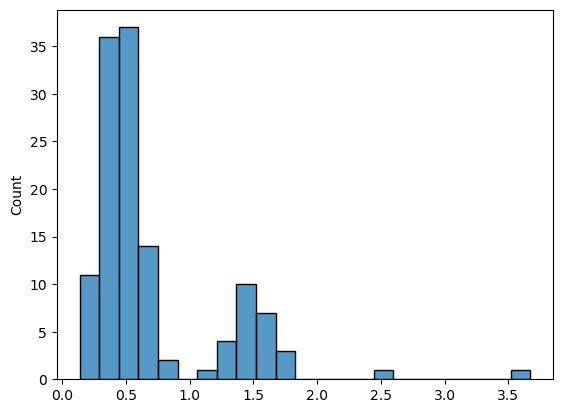

In [44]:
errors = np.abs(y_test - y_pred_test)

print("MAE:", errors.mean())
print("90° percentile:", np.percentile(errors, 90))
print("95° percentile:", np.percentile(errors, 95))
print("Max error:", errors.max())
sns.histplot(errors)